# Proyecto de clasificación de diabetes — Tercer corte
## Revisión del modelo, optimización y preparación para Streamlit

**Integrantes:** Shadia Romero, Valentina Cabrera, Santiago Echeverria y Tatiana Piedrahita.

**Problema:** clasificar si un paciente presenta diabetes (`Outcome = 1`) o no (`Outcome = 0`) a partir de 8 indicadores clínicos y demográficos.
**Datos:** Pima Indians Diabetes Database (768 registros, 9 columnas). Fuente de referencia: https://www.kaggle.com/datasets/hasibur013/diabetes-dataset

Este notebook (1) reconstruye el modelado con un pipeline sin fuga de información, (2) compara modelos con validación cruzada, (3) optimiza el modelo elegido registrando el antes y el después y (4) guarda el pipeline completo con `joblib` para la aplicación.

> **Cambio respecto al primer informe:** allí los ceros inválidos se reemplazaban por la mediana **antes** de dividir los datos (fuga de información). Ahora esa limpieza vive **dentro del pipeline** y se ajusta solo con los datos de entrenamiento.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, joblib, sklearn
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             make_scorer, fbeta_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from pipeline_utils import ZeroToNaN, FEATURES   # transformador propio (ceros -> NaN)

SEED = 42
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Carga de datos y división entrenamiento / prueba
La división se hace **antes** de cualquier imputación o escalado, de forma estratificada para conservar la proporción de clases.

In [2]:
df = pd.read_csv("diabetes.csv")   # CSV original con los 768 registros (ceros sin tratar)
print(df.shape, "| duplicados:", df.duplicated().sum())
print(df["Outcome"].value_counts().rename({0:"Sin diabetes", 1:"Con diabetes"}))
print("\nCeros por variable (posibles valores inválidos):")
print((df[FEATURES] == 0).sum())

X, y = df[FEATURES], df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("\nEntrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Proporción de diabetes -> train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

(768, 9) | duplicados: 0
Outcome
Sin diabetes    500
Con diabetes    268
Name: count, dtype: int64

Ceros por variable (posibles valores inválidos):
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

Entrenamiento: (614, 8) | Prueba: (154, 8)
Proporción de diabetes -> train: 0.349 | test: 0.351


## 2. Pipeline y métricas de evaluación
Cada modelo usa el mismo preprocesamiento, completamente dentro del pipeline:
`ceros inválidos → NaN` → `imputación por mediana` → `estandarización` → `clasificador`.

**Métrica de decisión.** En un problema de salud un **falso negativo** (no detectar a un paciente con diabetes) es más costoso que un falso positivo. Por eso no se elige solo por accuracy: se prioriza el **recall de la clase diabetes**, sin perder precisión ni estabilidad. Para optimizar se usa **F2** (pondera el recall el doble que la precisión).

In [3]:
def make_pipeline(clf):
    return Pipeline([
        ("zero_to_nan", ZeroToNaN()),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", clf),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def cv_summary(name, pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING)
    out = {"modelo": name}
    for m in SCORING:
        out[m] = r["test_" + m].mean()
    out["recall_std"] = r["test_recall"].std()
    out["f1_std"] = r["test_f1"].std()
    return out

## 3. Punto de partida: modelo base del segundo corte (Regresión Logística estándar)

In [4]:
base_pipe = make_pipeline(LogisticRegression(max_iter=2000, random_state=SEED))
base_cv = cv_summary("Regresión Logística (base)", base_pipe)
base_pipe.fit(X_train, y_train)
pb = base_pipe.predict(X_test)
base_test = dict(accuracy=accuracy_score(y_test,pb), precision=precision_score(y_test,pb),
                 recall=recall_score(y_test,pb), f1=f1_score(y_test,pb),
                 roc_auc=roc_auc_score(y_test, base_pipe.predict_proba(X_test)[:,1]))
print("VC (5 folds):", {k: round(v,3) for k,v in base_cv.items() if k!='modelo'})
print("Prueba      :", {k: round(v,3) for k,v in base_test.items()})
print("Matriz de confusión (prueba):\n", confusion_matrix(y_test, pb))

VC (5 folds): {'accuracy': np.float64(0.788), 'precision': np.float64(0.764), 'recall': np.float64(0.575), 'f1': np.float64(0.655), 'roc_auc': np.float64(0.843), 'recall_std': np.float64(0.023), 'f1_std': np.float64(0.024)}
Prueba      : {'accuracy': 0.708, 'precision': 0.6, 'recall': 0.5, 'f1': 0.545, 'roc_auc': 0.813}
Matriz de confusión (prueba):
 [[82 18]
 [27 27]]


**Diagnóstico del modelo base.** El accuracy es aceptable (supera 0,70), pero el **recall de la clase diabetes es bajo**: el modelo deja sin detectar a más de un tercio de los pacientes enfermos. Con las clases desbalanceadas (≈ 65 % / 35 %) el accuracy oculta ese problema, por eso se revisan otras opciones.

## 4. Comparación de modelos con validación cruzada estratificada (solo con datos de entrenamiento)

In [5]:
candidatos = {
    "Regresión Logística (base)": LogisticRegression(max_iter=2000, random_state=SEED),
    "Regresión Logística balanceada": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "KNN": KNeighborsClassifier(),
    "SVM balanceada": SVC(class_weight="balanced", probability=True, random_state=SEED),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Random Forest balanceado": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                       min_samples_leaf=3, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
comparacion = pd.DataFrame([cv_summary(n, make_pipeline(m)) for n, m in candidatos.items()]).set_index("modelo")
comparacion.round(3).sort_values("recall", ascending=False)

,accuracy,precision,recall,f1,roc_auc,recall_std,f1_std
modelo,,,,,,,
SVM balanceada,0.761,0.637,0.762,0.690,0.837,0.052,0.029
Árbol de decisión,0.707,0.561,0.748,0.637,0.786,0.118,0.052
Regresión Logística balanceada,0.762,0.649,0.701,0.672,0.844,0.039,0.013
Random Forest balanceado,0.782,0.693,0.682,0.685,0.832,0.046,0.014
Random Forest,0.769,0.699,0.603,0.646,0.821,0.026,0.030
Gradient Boosting,0.756,0.672,0.598,0.631,0.821,0.031,0.013
Regresión Logística (base),0.788,0.764,0.575,0.655,0.843,0.023,0.024
KNN,0.730,0.637,0.565,0.594,0.784,0.056,0.047


## 5. Optimización de hiperparámetros (GridSearchCV, métrica F2)
Se ajustan los tres candidatos más prometedores. La búsqueda usa **solo** el conjunto de entrenamiento.

In [6]:
f2 = make_scorer(fbeta_score, beta=2)
grids = {
    "Regresión Logística": (LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
                            {"classifier__C": [0.01, 0.1, 1, 10]}),
    "SVM": (SVC(class_weight="balanced", probability=True, random_state=SEED),
            {"classifier__C": [0.1, 1, 10], "classifier__gamma": ["scale", 0.01, 0.1], "classifier__kernel": ["rbf", "linear"]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=SEED),
                      {"classifier__max_depth": [3, 5, 8], "classifier__min_samples_leaf": [3, 5, 10]}),
}
tuned, filas = {}, []
for nombre, (clf, grid) in grids.items():
    gs = GridSearchCV(make_pipeline(clf), grid, scoring=f2, cv=cv, n_jobs=-1).fit(X_train, y_train)
    tuned[nombre] = gs.best_estimator_
    s = cv_summary(nombre + " (optimizada)", gs.best_estimator_)
    s["mejores_parametros"] = str(gs.best_params_)
    s["F2_cv"] = gs.best_score_
    filas.append(s)
optimizados = pd.DataFrame(filas).set_index("modelo")
optimizados.drop(columns="mejores_parametros").round(3)

,accuracy,precision,recall,f1,roc_auc,recall_std,f1_std,F2_cv
modelo,,,,,,,,
Regresión Logística (optimizada),0.767,0.651,0.720,0.682,0.845,0.050,0.017,0.704
SVM (optimizada),0.730,0.583,0.795,0.672,0.832,0.044,0.014,0.740
Random Forest (optimizada),0.780,0.662,0.762,0.707,0.839,0.032,0.018,0.739


In [7]:
for k, v in optimizados["mejores_parametros"].items():
    print(k, "->", v)

Regresión Logística (optimizada) -> {'classifier__C': 0.1}
SVM (optimizada) -> {'classifier__C': 0.1, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Random Forest (optimizada) -> {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10}


## 6. Selección del modelo final
Criterios (aplicados con la validación cruzada, **sin mirar el conjunto de prueba**): recall de la clase diabetes alto, accuracy ≥ 0,70, buen AUC y baja variabilidad entre folds.

El **Random Forest optimizado** (`max_depth=5`, `min_samples_leaf=10`, `class_weight="balanced_subsample"`) queda con el mejor equilibrio: recall alto y mejor accuracy y AUC que la SVM, con resultados estables. La Regresión Logística es más interpretable, pero detecta menos casos positivos.

In [8]:
final_model = tuned["Random Forest"]
final_cv = optimizados.loc["Random Forest (optimizada)"]
print("Modelo final:", final_model.named_steps["classifier"])
print("\nValidación cruzada (media ± desv.):")
r = cross_validate(final_model, X_train, y_train, cv=cv, scoring=SCORING)
for m in SCORING:
    print(f"  {m:10s}: {r['test_'+m].mean():.3f} ± {r['test_'+m].std():.3f}")

Modelo final: RandomForestClassifier(class_weight='balanced_subsample', max_depth=5,
                       min_samples_leaf=10, n_estimators=300, random_state=42)

Validación cruzada (media ± desv.):


  accuracy  : 0.780 ± 0.017
  precision : 0.662 ± 0.034
  recall    : 0.762 ± 0.032
  f1        : 0.707 ± 0.018
  roc_auc   : 0.839 ± 0.019


## 7. Evaluación final en el conjunto de prueba (se usa una sola vez)

{'accuracy': 0.74, 'precision': 0.6, 'recall': 0.778, 'f1': 0.677, 'roc_auc': 0.82}

              precision    recall  f1-score   support

Sin diabetes       0.86      0.72      0.78       100
Con diabetes       0.60      0.78      0.68        54

    accuracy                           0.74       154
   macro avg       0.73      0.75      0.73       154
weighted avg       0.77      0.74      0.75       154



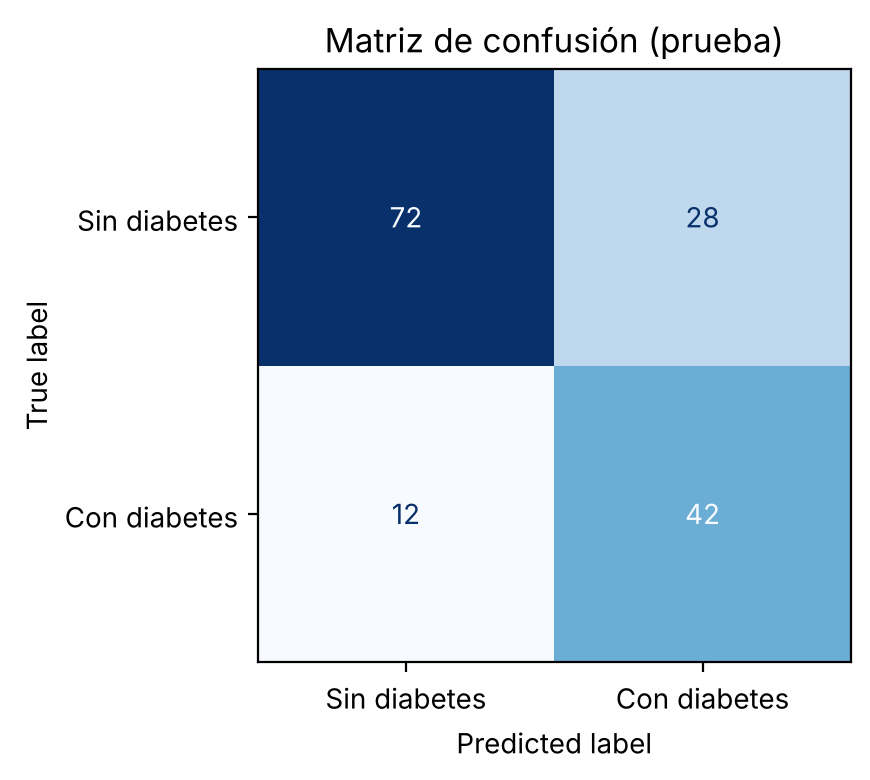

In [9]:
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

final_test = dict(accuracy=accuracy_score(y_test,y_pred), precision=precision_score(y_test,y_pred),
                  recall=recall_score(y_test,y_pred), f1=f1_score(y_test,y_pred), roc_auc=roc_auc_score(y_test,y_proba))
cm = confusion_matrix(y_test, y_pred)
print({k: round(v,3) for k,v in final_test.items()})
print()
print(classification_report(y_test, y_pred, target_names=["Sin diabetes","Con diabetes"]))

fig, ax = plt.subplots(figsize=(4.5,4))
ConfusionMatrixDisplay(cm, display_labels=["Sin diabetes","Con diabetes"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (prueba)"); plt.tight_layout(); plt.show()

## 8. Comparación antes y después

In [10]:
antes_despues = pd.DataFrame({
    "Base (Reg. Logística) — prueba": base_test,
    "Final (Random Forest optimizado) — prueba": final_test,
}).T.round(3)
antes_despues["falsos_negativos"] = [int(confusion_matrix(y_test,pb)[1,0]), int(cm[1,0])]
antes_despues

,accuracy,precision,recall,f1,roc_auc,falsos_negativos
Base (Reg. Logística) — prueba,0.708,0.6,0.500,0.545,0.813,27
Final (Random Forest optimizado) — prueba,0.740,0.6,0.778,0.677,0.820,12


**Lectura.** Al pasar del modelo base al final el **recall de la clase diabetes sube** y los **falsos negativos disminuyen**, a cambio de menos precisión en validación cruzada (≈ 0,76 → 0,66); en el conjunto de prueba la precisión se mantuvo en 0,60. El accuracy se mantiene por encima de 0,70. Con 154 registros de prueba, estas cifras tienen incertidumbre (un caso cambia el recall ≈ 1,9 puntos), por eso se apoyan también en la validación cruzada.

## 9. Variables más influyentes

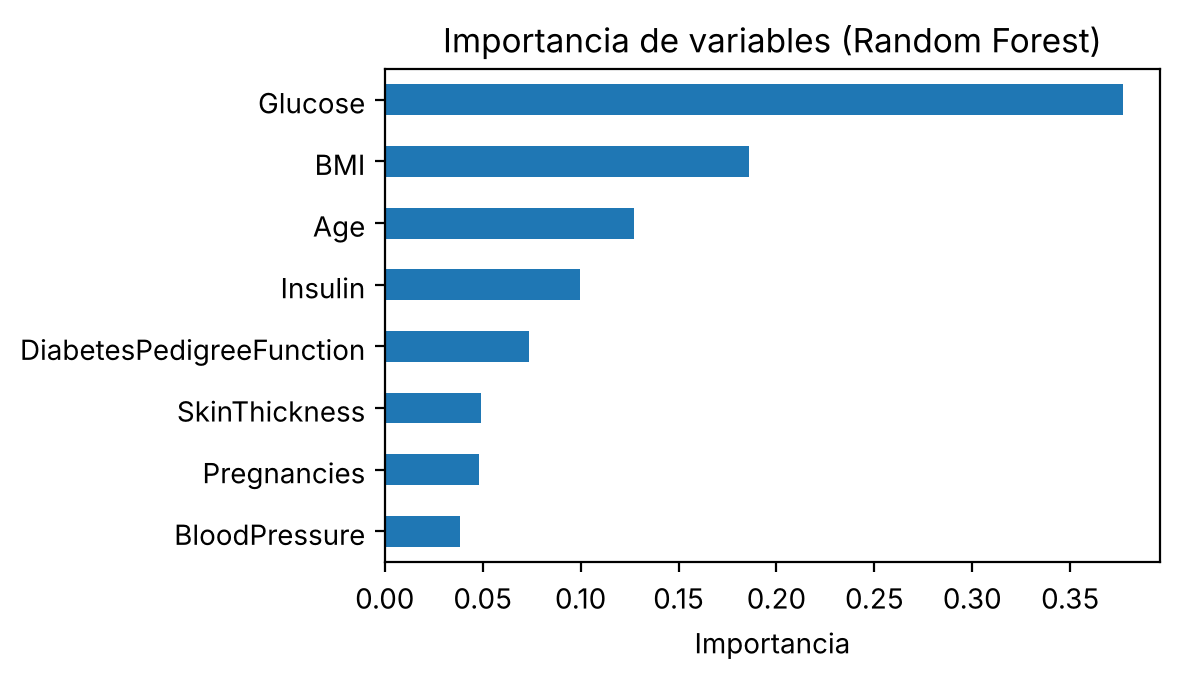

Glucose                     0.377
BMI                         0.186
Age                         0.127
Insulin                     0.100
DiabetesPedigreeFunction    0.074
SkinThickness               0.049
Pregnancies                 0.048
BloodPressure               0.038
dtype: float64

In [11]:
rf = final_model.named_steps["classifier"]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(6,3.5), title="Importancia de variables (Random Forest)")
plt.xlabel("Importancia"); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

## 10. Revisión de calidad del modelado (Ficha técnica)
| Aspecto | Revisión |
|---|---|
| Tratamiento de datos | Ceros inválidos → NaN e imputación por mediana **dentro del pipeline**. |
| Separación train/test | 80/20 estratificada y con semilla fija, antes de cualquier transformación. |
| Fuga de información | Corregida: imputador y escalador se ajustan solo con entrenamiento (en cada fold de la VC también). |
| Validación cruzada | 5 folds estratificados; se reportan media y desviación estándar. |
| Desbalance (≈ 65/35) | `class_weight="balanced_subsample"` y análisis de recall, no solo de accuracy. |
| Colinealidad | Los modelos de árboles no se ven afectados; la correlación máxima entre variables es moderada. |
| Sobreajuste | Se limita `max_depth` y `min_samples_leaf`; se compara VC vs. prueba. |
| Hiperparámetros | GridSearchCV con F2 solo sobre entrenamiento. |

In [12]:
corr = X_train.replace(0, np.nan).corr().abs().to_numpy().copy()
np.fill_diagonal(corr, 0)
print("Correlación absoluta máxima entre variables:", round(corr.max(), 3))
gap = final_cv["accuracy"] - final_test["accuracy"]
print(f"Accuracy VC = {final_cv['accuracy']:.3f} | Accuracy prueba = {final_test['accuracy']:.3f} | diferencia = {gap:+.3f}")

Correlación absoluta máxima entre variables: 0.636
Accuracy VC = 0.780 | Accuracy prueba = 0.740 | diferencia = +0.040


## 11. Guardar el pipeline completo y los artefactos para Streamlit

In [13]:
joblib.dump(final_model, "modelo_diabetes_pipeline.joblib", compress=3)

# Registro conocido del conjunto de prueba para comparar con la app (punto 4 de la actividad)
idx = int(X_test.index[0])
row = X_test.loc[[idx]]
verificacion = {
    "indice_original": idx,
    "entrada": {k: float(v) for k, v in row.iloc[0].items()},
    "probabilidad_diabetes": float(final_model.predict_proba(row)[0, 1]),
    "prediccion": int(final_model.predict(row)[0]),
    "valor_real": int(y_test.loc[idx]),
}
print(json.dumps(verificacion, indent=2))

metrics = {
    "modelo_final": "Random Forest optimizado",
    "parametros": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in final_model.named_steps["classifier"].get_params().items()
                   if k in ("n_estimators","max_depth","min_samples_leaf","class_weight")},
    "prueba": {k: float(v) for k, v in final_test.items()},
    "confusion_matrix": cm.tolist(),
    "test_size": int(len(y_test)), "train_size": int(len(y_train)),
    "validacion_cruzada": {m: {"media": float(r["test_"+m].mean()), "std": float(r["test_"+m].std())} for m in SCORING},
    "base_prueba": {k: float(v) for k, v in base_test.items()},
    "base_confusion_matrix": confusion_matrix(y_test, pb).tolist(),
    "importancias": {k: float(v) for k, v in imp.sort_values(ascending=False).items()},
    "comparacion_modelos": comparacion.round(4).reset_index().to_dict(orient="records"),
    "positive_label": "Outcome = 1 (diabetes)",
    "sklearn_version": sklearn.__version__,
}
with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
with open("verificacion_registro.json", "w", encoding="utf-8") as f:
    json.dump(verificacion, f, indent=2)
print("\nGuardados: modelo_diabetes_pipeline.joblib, metrics.json, verificacion_registro.json")

{
  "indice_original": 44,
  "entrada": {
    "Pregnancies": 7.0,
    "Glucose": 159.0,
    "BloodPressure": 64.0,
    "SkinThickness": 0.0,
    "Insulin": 0.0,
    "BMI": 27.4,
    "DiabetesPedigreeFunction": 0.294,
    "Age": 40.0
  },
  "probabilidad_diabetes": 0.642660443445773,
  "prediccion": 1,
  "valor_real": 0
}

Guardados: modelo_diabetes_pipeline.joblib, metrics.json, verificacion_registro.json


In [14]:
# Prueba de recarga: el archivo guardado debe reproducir exactamente las predicciones
loaded = joblib.load("modelo_diabetes_pipeline.joblib")
assert np.allclose(loaded.predict_proba(X_test), final_model.predict_proba(X_test))
print("OK: el pipeline guardado reproduce las predicciones del notebook.")

OK: el pipeline guardado reproduce las predicciones del notebook.


## 12. Registro de uso de IA generativa (tercer corte)
La herramienta, el prompt principal, la verificación y los ajustes se documentan en el `README.md` del repositorio.